<center><h1>Chun-Fu_Liu_HW5</h1></center>
<br>
<br>

Name: Chun-Fu Liu
<br>
Github Username: Albert927
<br>
USC ID: 5635413630

## 1. Decision Trees as Interpretable Models

Import packages

In [12]:
import pandas as pd
from pathlib import Path
import pandas as pd

DATA_DIR = Path(r"C:\Users\liual\Desktop\DSCI 552\HW\hw5\Data")

### (a) Obtain Data

Get the Accute Inamations Data Set

In [13]:
columns = [
    "temperature",
    "nausea",
    "lumbar_pain",
    "urine_pushing",
    "micturition_pain",
    "urethra_burning",
    "bladder_inflammation",
    "renal_pelvis_nephritis",
]

diagnosis = pd.read_csv(
    DATA_DIR / "diagnosis.data",
    sep="\t",
    encoding="utf-16",
    decimal=",",
    header=None,
    names=columns,
)

# Encode yes/no values as 1/0 for all columns except temperature.
for column in columns[1:]:
    diagnosis[column] = diagnosis[column].map({"no": 0, "yes": 1})

X_diagnosis = diagnosis.iloc[:, :6]
y_diagnosis = diagnosis.iloc[:, 6:]

print("Dataset shape:", diagnosis.shape)
print("Feature matrix shape:", X_diagnosis.shape)
print("Target matrix shape:", y_diagnosis.shape)
print("Total missing values:", diagnosis.isna().sum().sum())

display(diagnosis.head())

Dataset shape: (120, 8)
Feature matrix shape: (120, 6)
Target matrix shape: (120, 2)
Total missing values: 0


,temperature,nausea,lumbar_pain,urine_pushing,micturition_pain,urethra_burning,bladder_inflammation,renal_pelvis_nephritis
0,35.5,0,1,0,0,0,0,0
1,35.9,0,0,1,1,1,1,0
2,35.9,0,1,0,0,0,0,0
3,36.0,0,0,1,1,1,1,0
4,36.0,0,1,0,0,0,0,0


### (b) Build a decision tree

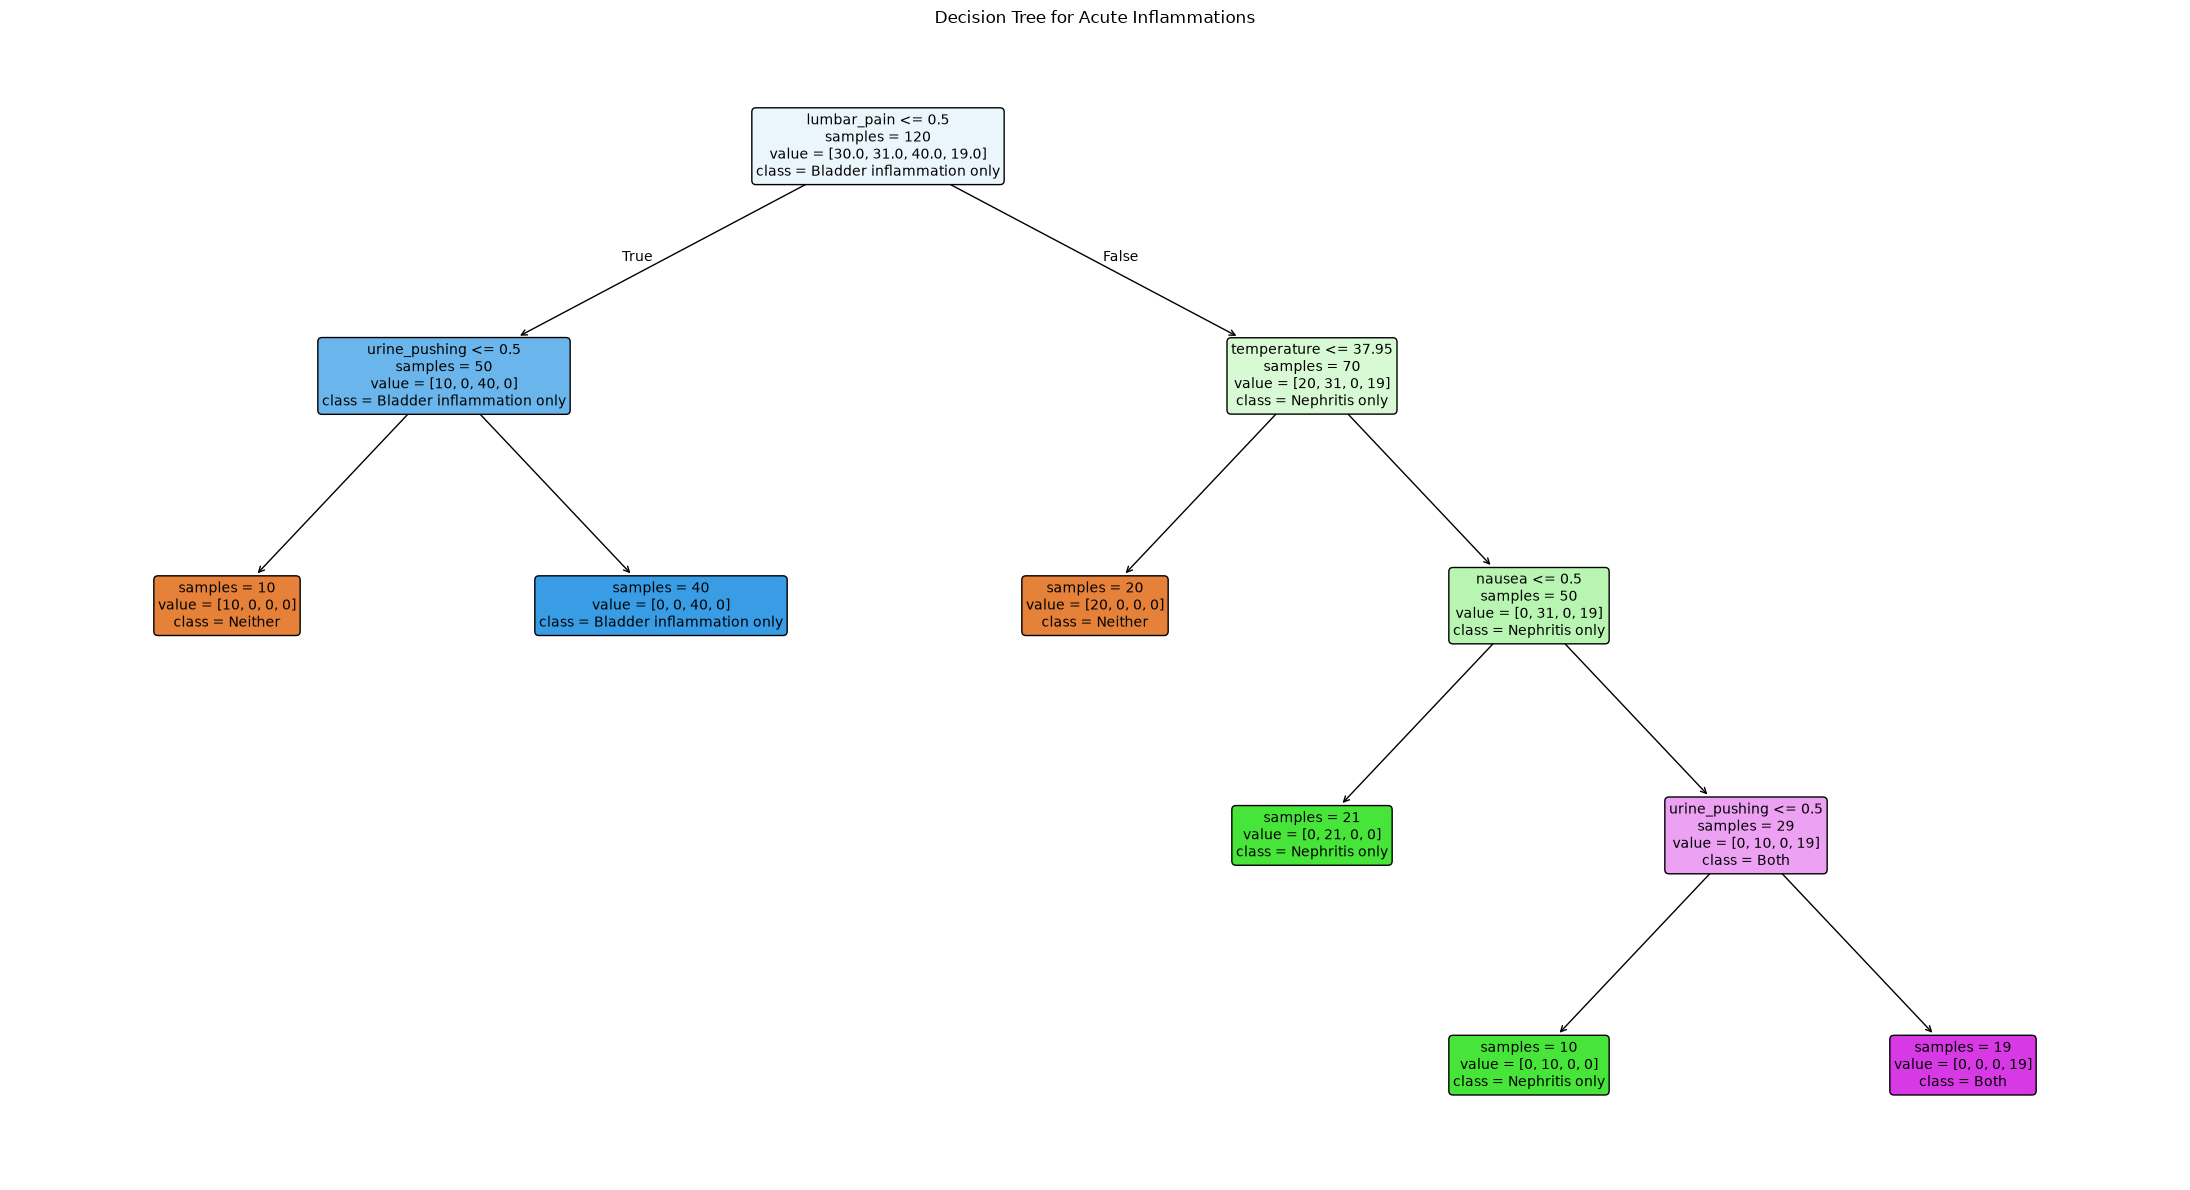

Tree depth: 4
Number of leaves: 6
Training accuracy: 1.000


In [14]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Encode each pair of diagnosis labels as one class.
y_combined = (
    2 * y_diagnosis["bladder_inflammation"]
    + y_diagnosis["renal_pelvis_nephritis"]
)

diagnosis_labels = {
    0: "Neither",
    1: "Nephritis only",
    2: "Bladder inflammation only",
    3: "Both",
}

# Fit the decision tree using the entire dataset.
decision_tree = DecisionTreeClassifier(random_state=42)
decision_tree.fit(X_diagnosis, y_combined)

# Match class names to the order used by the fitted model.
class_names = [
    diagnosis_labels[label]
    for label in decision_tree.classes_
]

plt.figure(figsize=(22, 12))

plot_tree(
    decision_tree,
    feature_names=X_diagnosis.columns.tolist(),
    class_names=class_names,
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=10,
)

plt.title("Decision Tree for Acute Inflammations")
plt.tight_layout()
plt.show()

print("Tree depth:", decision_tree.get_depth())
print("Number of leaves:", decision_tree.get_n_leaves())
print(
    "Training accuracy:",
    f"{decision_tree.score(X_diagnosis, y_combined):.3f}",
)

### (c) Convert the decision rules

In [15]:
import numpy as np
from sklearn.tree import _tree


def extract_rules(model, feature_names, class_labels):
    tree = model.tree_
    rules = []

    def traverse(node_id, conditions):
        feature_index = tree.feature[node_id]

        if feature_index != _tree.TREE_UNDEFINED:
            feature_name = feature_names[feature_index]
            threshold = tree.threshold[node_id]

            if feature_name == "temperature":
                left_condition = f"{feature_name} <= {threshold:.2f}"
                right_condition = f"{feature_name} > {threshold:.2f}"
            else:
                left_condition = f"{feature_name} = no"
                right_condition = f"{feature_name} = yes"

            traverse(
                tree.children_left[node_id],
                conditions + [left_condition],
            )
            traverse(
                tree.children_right[node_id],
                conditions + [right_condition],
            )
        else:
            class_index = np.argmax(tree.value[node_id].reshape(-1))
            predicted_class = model.classes_[class_index]
            prediction = class_labels[predicted_class]

            condition_text = " AND ".join(conditions) or "TRUE"
            sample_count = tree.n_node_samples[node_id]

            rules.append(
                f"IF {condition_text} THEN {prediction} "
                f"(training samples: {sample_count})"
            )

    traverse(0, [])
    return rules


decision_rules = extract_rules(
    decision_tree,
    X_diagnosis.columns.tolist(),
    diagnosis_labels,
)

for rule_number, rule in enumerate(decision_rules, start=1):
    print(f"Rule {rule_number}: {rule}")

print("Number of rules:", len(decision_rules))

assert len(decision_rules) == decision_tree.get_n_leaves()

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN Neither (training samples: 10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN Bladder inflammation only (training samples: 40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN Neither (training samples: 20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = no THEN Nephritis only (training samples: 21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no THEN Nephritis only (training samples: 10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes THEN Both (training samples: 19)
Number of rules: 6


### (d) Cost-complexity pruning

In [16]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Obtain candidate pruning strengths.
pruning_path = decision_tree.cost_complexity_pruning_path(
    X_diagnosis,
    y_combined,
)

candidate_alphas = np.unique(pruning_path.ccp_alphas)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

records = []

for alpha in candidate_alphas:
    model = DecisionTreeClassifier(
        ccp_alpha=float(alpha),
        random_state=42,
    )

    scores = cross_val_score(
        model,
        X_diagnosis,
        y_combined,
        cv=cv,
        scoring="accuracy",
    )

    model.fit(X_diagnosis, y_combined)

    records.append({
        "alpha": float(alpha),
        "cv_mean_accuracy": scores.mean(),
        "cv_standard_error": scores.std(ddof=1) / np.sqrt(len(scores)),
        "depth": model.get_depth(),
        "leaves": model.get_n_leaves(),
    })

pruning_results = pd.DataFrame(records)

# Apply the one-standard-error rule.
best_index = pruning_results["cv_mean_accuracy"].idxmax()
best_result = pruning_results.loc[best_index]

accuracy_threshold = (
    best_result["cv_mean_accuracy"]
    - best_result["cv_standard_error"]
)

eligible_models = pruning_results[
    pruning_results["cv_mean_accuracy"] >= accuracy_threshold
]

selected_result = eligible_models.sort_values("alpha").iloc[-1]
selected_alpha = float(selected_result["alpha"])

pruned_tree = DecisionTreeClassifier(
    ccp_alpha=selected_alpha,
    random_state=42,
)
pruned_tree.fit(X_diagnosis, y_combined)

display(pruning_results)

print("Selected alpha:", selected_alpha)
print("CV accuracy threshold:", f"{accuracy_threshold:.3f}")
print("Pruned tree depth:", pruned_tree.get_depth())
print("Pruned tree leaves:", pruned_tree.get_n_leaves())
print(
    "Pruned training accuracy:",
    f"{pruned_tree.score(X_diagnosis, y_combined):.3f}",
)

,alpha,cv_mean_accuracy,cv_standard_error,depth,leaves
0,0.000000,0.991667,0.008333,4,6
1,0.098167,0.858333,0.025000,2,4
2,0.133333,0.758333,0.033333,2,3
3,0.182000,0.666667,0.029463,1,2
4,0.222917,0.483333,0.061237,0,1


Selected alpha: 0.0
CV accuracy threshold: 0.983
Pruned tree depth: 4
Pruned tree leaves: 6
Pruned training accuracy: 1.000


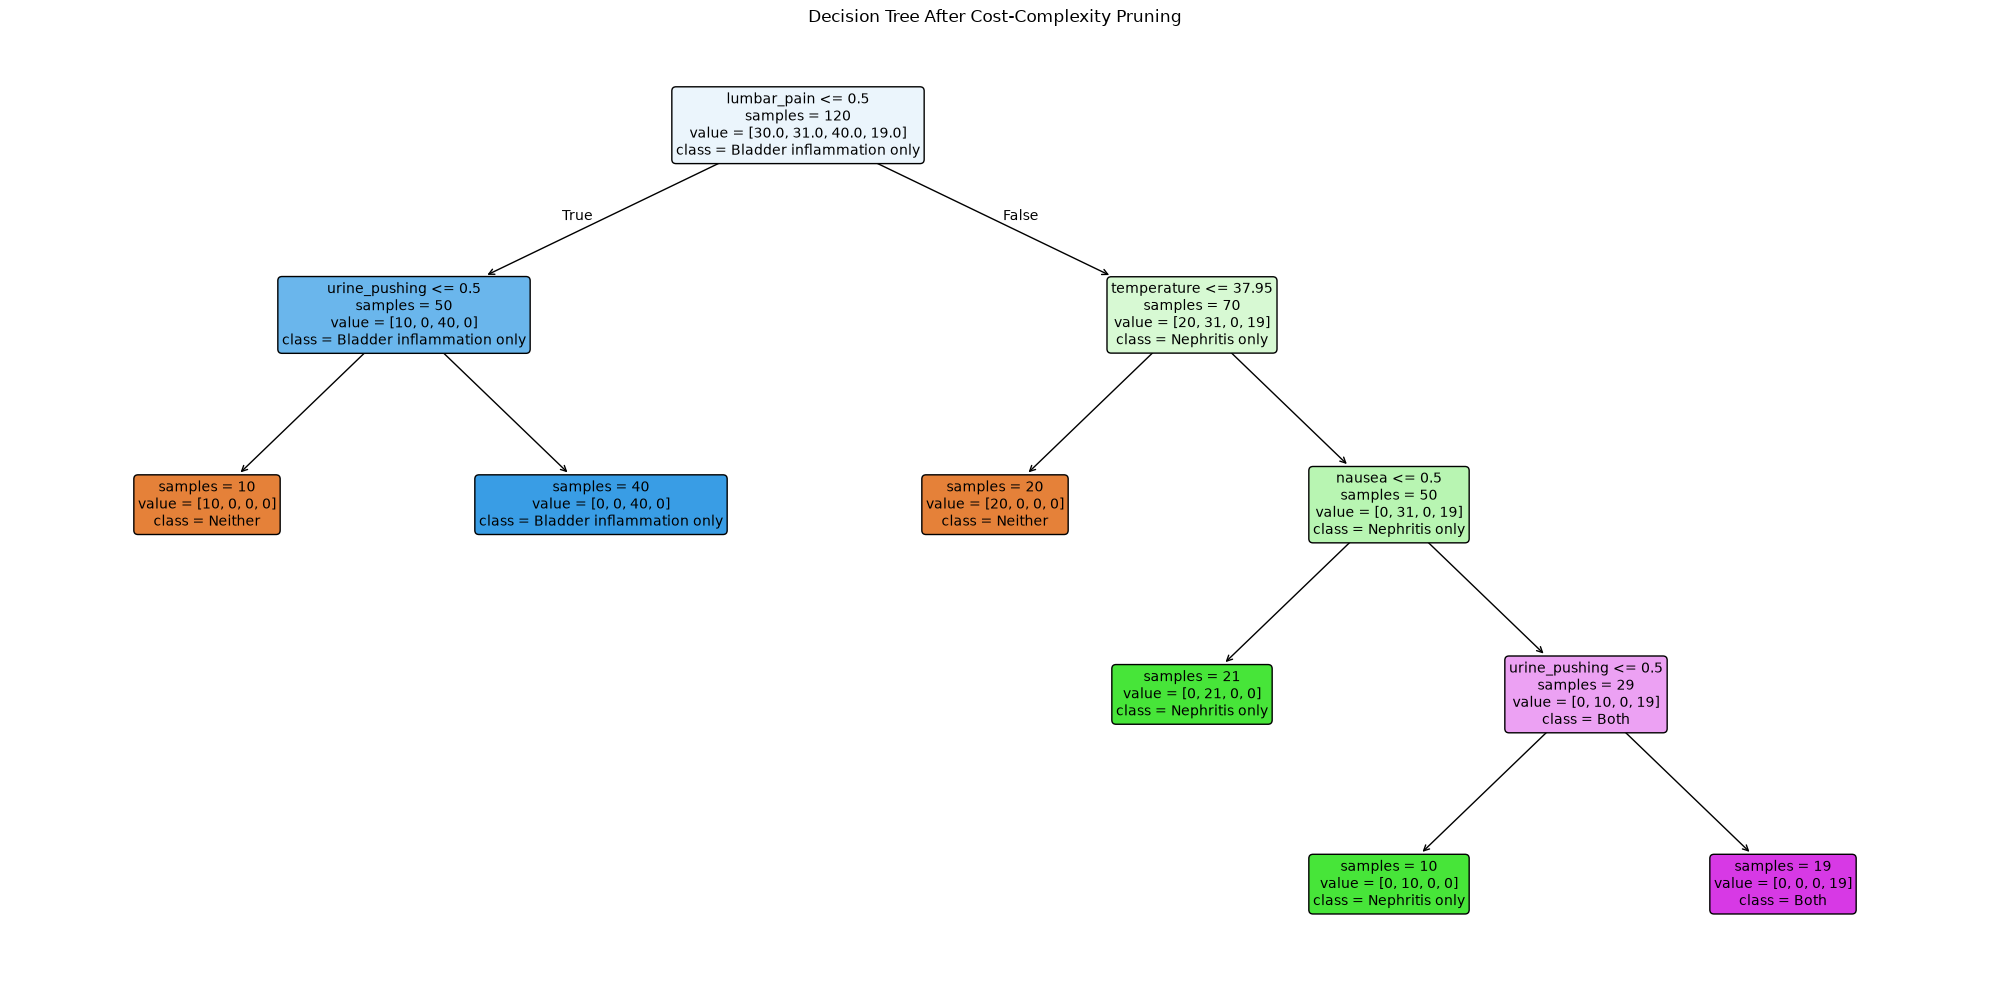

Rule 1: IF lumbar_pain = no AND urine_pushing = no THEN Neither (training samples: 10)
Rule 2: IF lumbar_pain = no AND urine_pushing = yes THEN Bladder inflammation only (training samples: 40)
Rule 3: IF lumbar_pain = yes AND temperature <= 37.95 THEN Neither (training samples: 20)
Rule 4: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = no THEN Nephritis only (training samples: 21)
Rule 5: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = no THEN Nephritis only (training samples: 10)
Rule 6: IF lumbar_pain = yes AND temperature > 37.95 AND nausea = yes AND urine_pushing = yes THEN Both (training samples: 19)
Number of pruned rules: 6


In [17]:
plt.figure(figsize=(20, 10))

plot_tree(
    pruned_tree,
    feature_names=X_diagnosis.columns.tolist(),
    class_names=[
        diagnosis_labels[label]
        for label in pruned_tree.classes_
    ],
    filled=True,
    rounded=True,
    impurity=False,
    fontsize=10,
)

plt.title("Decision Tree After Cost-Complexity Pruning")
plt.tight_layout()
plt.show()

pruned_rules = extract_rules(
    pruned_tree,
    X_diagnosis.columns.tolist(),
    diagnosis_labels,
)

for rule_number, rule in enumerate(pruned_rules, start=1):
    print(f"Rule {rule_number}: {rule}")

print("Number of pruned rules:", len(pruned_rules))

Five-fold stratified cross-validation was used to evaluate the
candidate cost-complexity pruning parameters. The one-standard-error
rule selected alpha = 0.0.

The selected tree has a depth of 4 and 6 leaves. Its mean
cross-validation accuracy is 0.9917, and its training accuracy is
1.0000. The next smaller candidate has 4 leaves, but its mean
cross-validation accuracy drops to 0.8583, below the acceptance
threshold of 0.9833.

Therefore, the original tree was retained. It is the smallest
candidate tree satisfying the chosen accuracy threshold, and its
six IF-THEN rules remain unchanged.

## 2. The LASSO and Boosting for Regression

### (a) Obtain Data

In [18]:
# Read column names from the dataset documentation.
attribute_names = []

with open(
    DATA_DIR / "communities.names",
    encoding="utf-8",
) as file:
    for line in file:
        if line.strip().lower().startswith("@attribute "):
            attribute_names.append(line.split()[1])

# Read the dataset and interpret question marks as missing values.
communities = pd.read_csv(
    DATA_DIR / "communities.data",
    header=None,
    names=attribute_names,
    na_values="?",
)

# Split the data in the original row order.
train_data = communities.iloc[:1495].copy()
test_data = communities.iloc[1495:].copy()

print("Full dataset shape:", communities.shape)
print("Training set shape:", train_data.shape)
print("Test set shape:", test_data.shape)
print("Target column:", communities.columns[-1])

display(train_data.head())

assert communities.shape == (1994, 128)
assert len(train_data) == 1495
assert len(test_data) == 499
assert communities.columns[-1] == "ViolentCrimesPerPop"

Full dataset shape: (1994, 128)
Training set shape: (1495, 128)
Test set shape: (499, 128)
Target column: ViolentCrimesPerPop


,state,county,community,communityname,fold,population,householdsize,racepctblack,racePctWhite,racePctAsian,...,LandArea,PopDens,PctUsePubTrans,PolicCars,PolicOperBudg,LemasPctPolicOnPatr,LemasGangUnitDeploy,LemasPctOfficDrugUn,PolicBudgPerPop,ViolentCrimesPerPop
0,8,NaN,NaN,Lakewoodcity,1,0.19,0.33,0.02,0.90,0.12,...,0.12,0.26,0.20,0.06,0.04,0.9,0.5,0.32,0.14,0.20
1,53,NaN,NaN,Tukwilacity,1,0.00,0.16,0.12,0.74,0.45,...,0.02,0.12,0.45,NaN,NaN,NaN,NaN,0.00,NaN,0.67
2,24,NaN,NaN,Aberdeentown,1,0.00,0.42,0.49,0.56,0.17,...,0.01,0.21,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.43
3,34,5.0,81440.0,Willingborotownship,1,0.04,0.77,1.00,0.08,0.12,...,0.02,0.39,0.28,NaN,NaN,NaN,NaN,0.00,NaN,0.12
4,42,95.0,6096.0,Bethlehemtownship,1,0.01,0.55,0.02,0.95,0.09,...,0.04,0.09,0.02,NaN,NaN,NaN,NaN,0.00,NaN,0.03


### (b) Missing values

In [19]:
from sklearn.impute import SimpleImputer

non_predictive_columns = [
    "state",
    "county",
    "community",
    "communityname",
    "fold",
]

target_column = "ViolentCrimesPerPop"

# Separate predictors and target values.
X_train_raw = train_data.drop(
    columns=non_predictive_columns + [target_column]
)
X_test_raw = test_data.drop(
    columns=non_predictive_columns + [target_column]
)

y_train = train_data[target_column].copy()
y_test = test_data[target_column].copy()

# Inspect missing values in the training predictors.
missing_counts = X_train_raw.isna().sum()

print("Features with missing training values:")
display(
    missing_counts[missing_counts > 0]
    .sort_values(ascending=False)
    .rename("missing_count")
    .to_frame()
)

# Confirm that every feature has at least one observed training value.
assert not X_train_raw.isna().all().any()
assert not y_train.isna().any()
assert not y_test.isna().any()

# Learn imputation means from the training set only.
imputer = SimpleImputer(strategy="mean")

X_train = pd.DataFrame(
    imputer.fit_transform(X_train_raw),
    columns=X_train_raw.columns,
    index=X_train_raw.index,
)

X_test = pd.DataFrame(
    imputer.transform(X_test_raw),
    columns=X_test_raw.columns,
    index=X_test_raw.index,
)

print("Training feature matrix shape:", X_train.shape)
print("Test feature matrix shape:", X_test.shape)
print("Missing training values after imputation:", X_train.isna().sum().sum())
print("Missing test values after imputation:", X_test.isna().sum().sum())

assert X_train.shape == (1495, 122)
assert X_test.shape == (499, 122)
assert not X_train.isna().any().any()
assert not X_test.isna().any().any()

Features with missing training values:


,missing_count
LemasSwornFT,1256
LemasSwFTPerPop,1256
LemasSwFTFieldOps,1256
LemasTotalReq,1256
LemasSwFTFieldPerPop,1256
LemasTotReqPerPop,1256
PolicReqPerOffic,1256
OfficAssgnDrugUnits,1256
PolicPerPop,1256
RacialMatchCommPol,1256


Training feature matrix shape: (1495, 122)
Test feature matrix shape: (499, 122)
Missing training values after imputation: 0
Missing test values after imputation: 0


### (c) Plot a correlation matrix

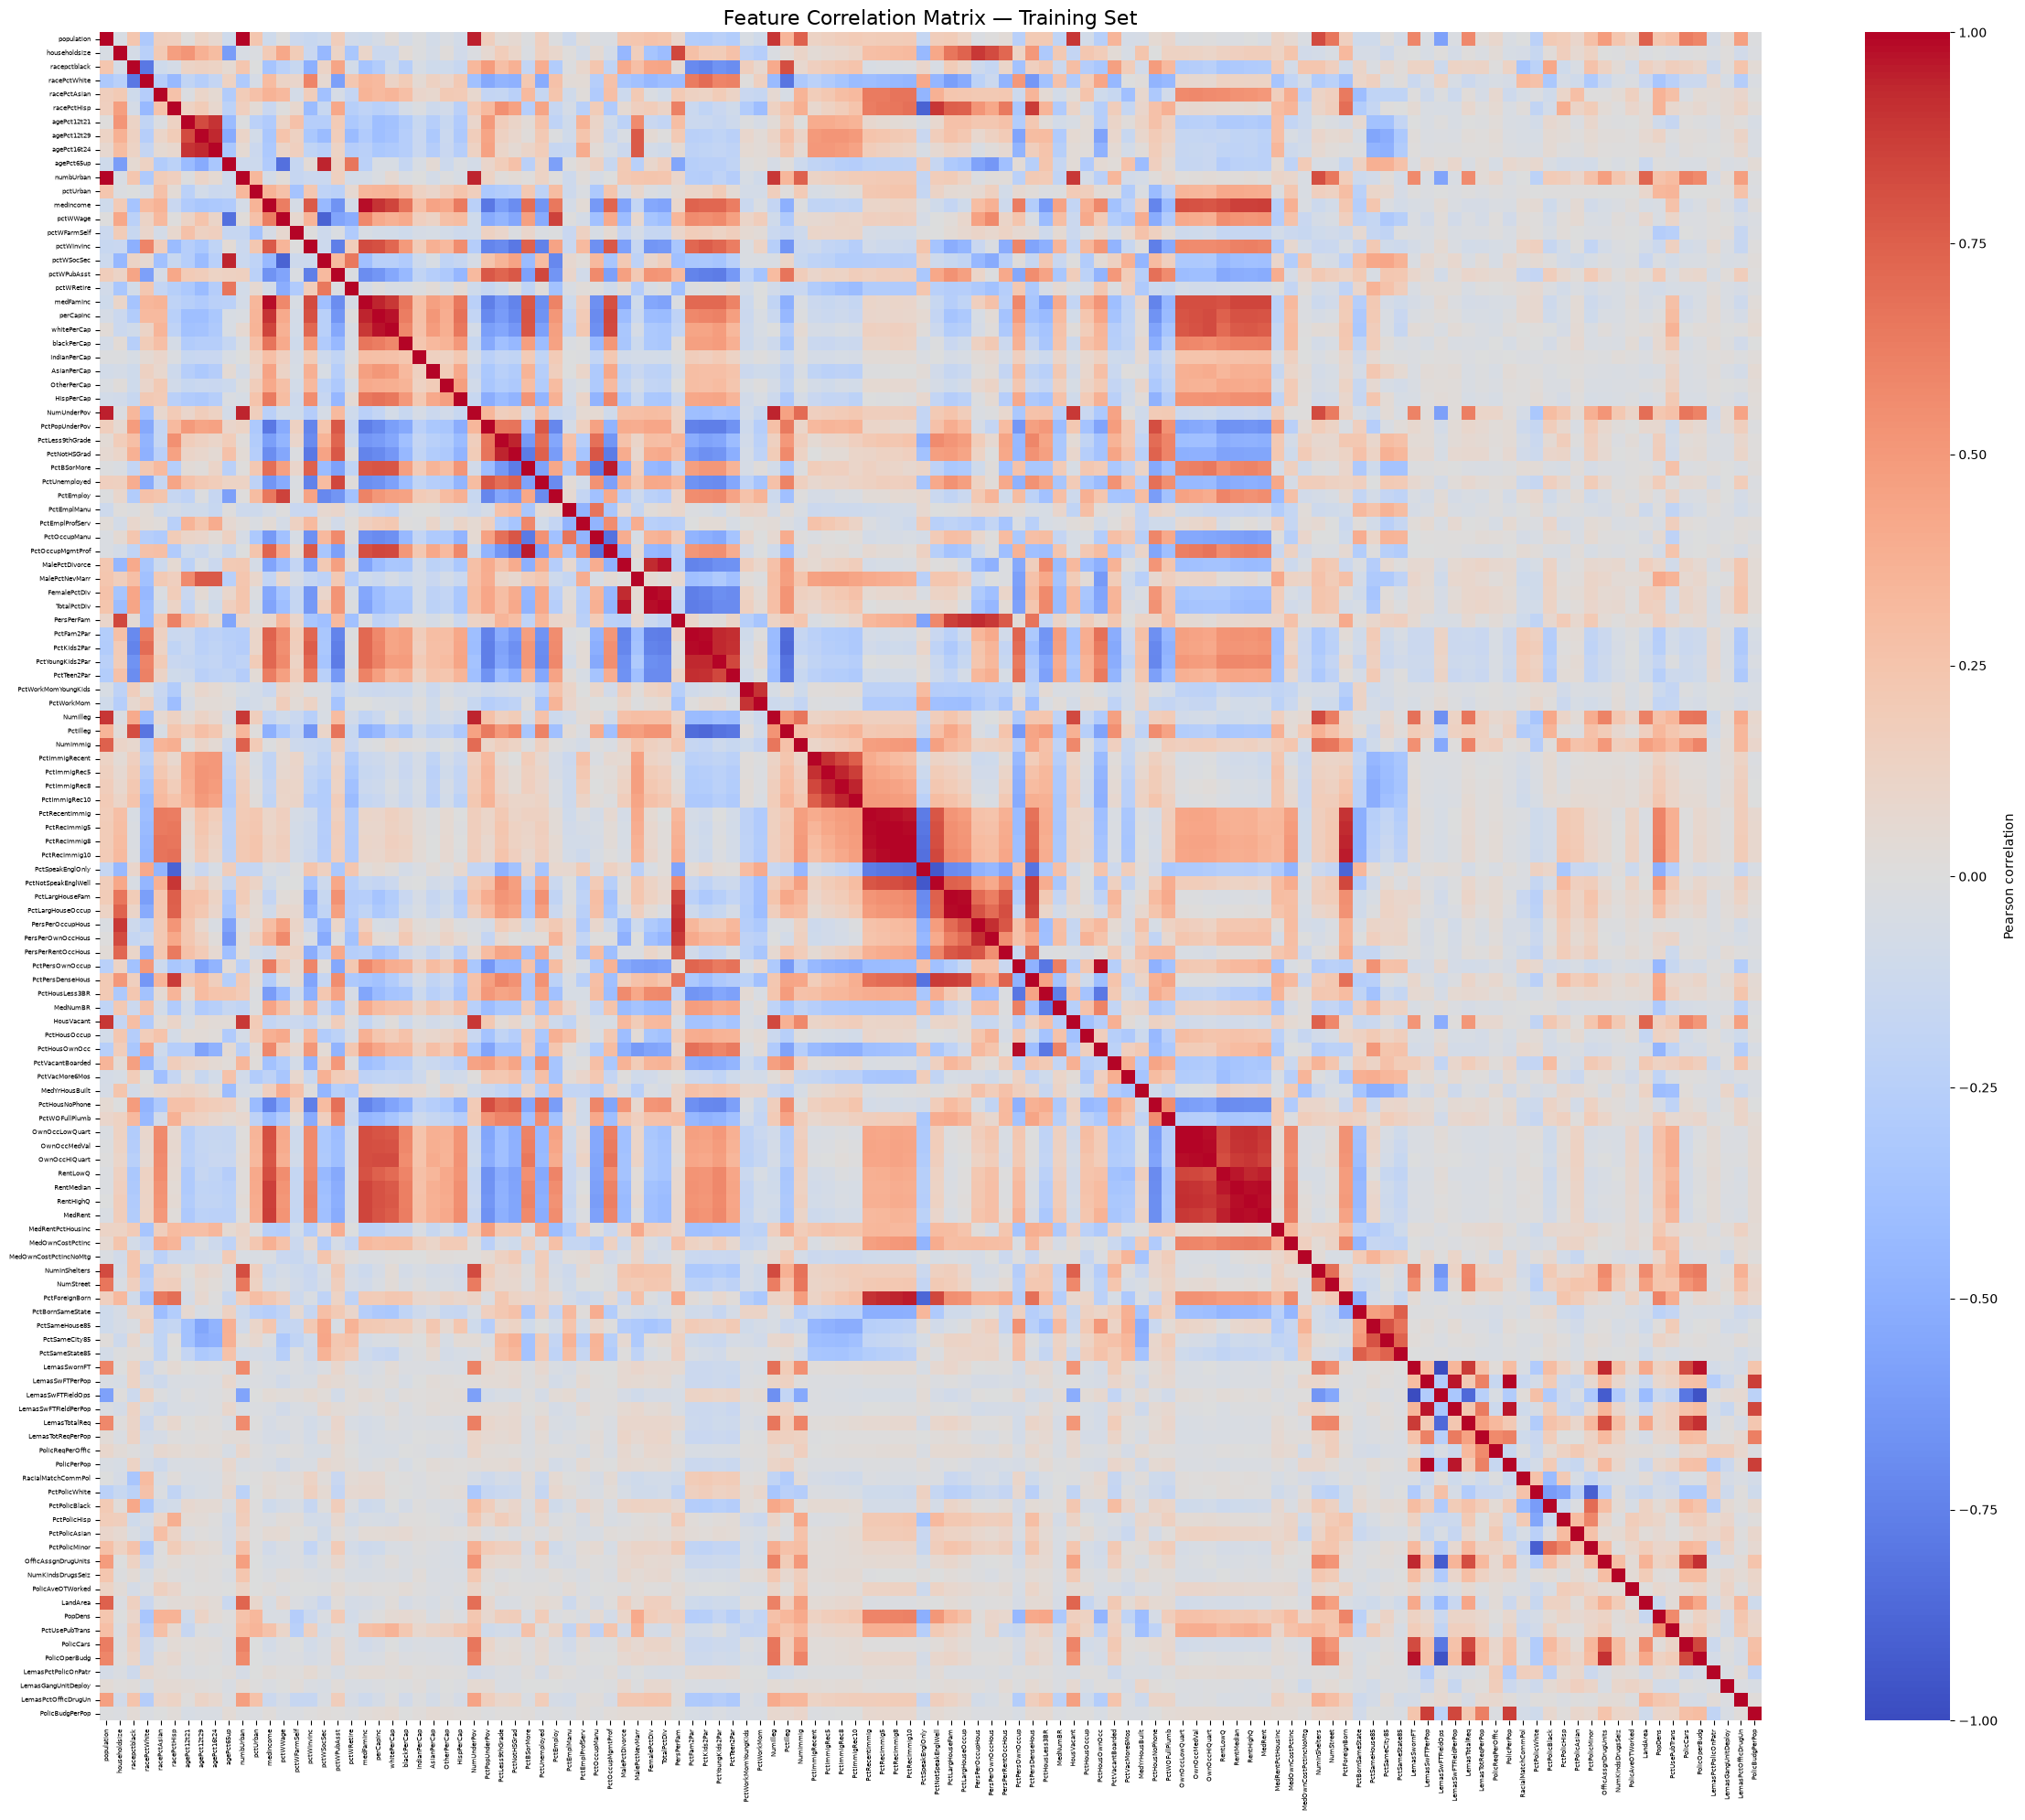

Correlation matrix shape: (122, 122)


In [20]:
import seaborn as sns

# Calculate correlations between training predictors.
correlation_matrix = X_train.corr(method="pearson")

plt.figure(figsize=(24, 20))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=True,
    yticklabels=True,
    annot=False,
    cbar_kws={"label": "Pearson correlation"},
)

plt.title("Feature Correlation Matrix — Training Set", fontsize=16)
plt.xticks(rotation=90, fontsize=5)
plt.yticks(rotation=0, fontsize=5)
plt.tight_layout()
plt.show()

print("Correlation matrix shape:", correlation_matrix.shape)

### (d) Calculate the Coefficient of Variation CV

In [21]:
# Calculate feature statistics using the imputed training data.
feature_means = X_train.mean()
feature_std = X_train.std(ddof=1)

# Treat CV as undefined when the feature mean is zero.
feature_cv = feature_std / feature_means.replace(0, np.nan)

cv_summary = pd.DataFrame({
    "mean": feature_means,
    "sample_std": feature_std,
    "coefficient_of_variation": feature_cv,
}).sort_values(
    "coefficient_of_variation",
    ascending=False,
    na_position="last",
)

display(cv_summary)

print("Number of features:", len(cv_summary))
print(
    "Features with undefined CV:",
    cv_summary["coefficient_of_variation"].isna().sum(),
)

,mean,sample_std,coefficient_of_variation
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
...,...,...,...
NumKindsDrugsSeiz,0.552050,0.079706,0.144382
RacialMatchCommPol,0.682301,0.092010,0.134853
PctPolicWhite,0.725314,0.089078,0.122813
LemasPctPolicOnPatr,0.713054,0.082528,0.115739


Number of features: 122
Features with undefined CV: 0


### (e) Scatter plots and box plots for highest CV features

,mean,sample_std,coefficient_of_variation
NumStreet,0.022983,0.098665,4.292923
NumInShelters,0.029599,0.102736,3.470952
NumIlleg,0.037204,0.113806,3.058964
NumImmig,0.030595,0.089541,2.926635
LemasPctOfficDrugUn,0.093304,0.238201,2.552946
NumUnderPov,0.056849,0.133167,2.342443
population,0.058167,0.130359,2.241105
numbUrban,0.064649,0.131784,2.038461
HousVacant,0.076475,0.150538,1.968467
LandArea,0.064107,0.105482,1.645408


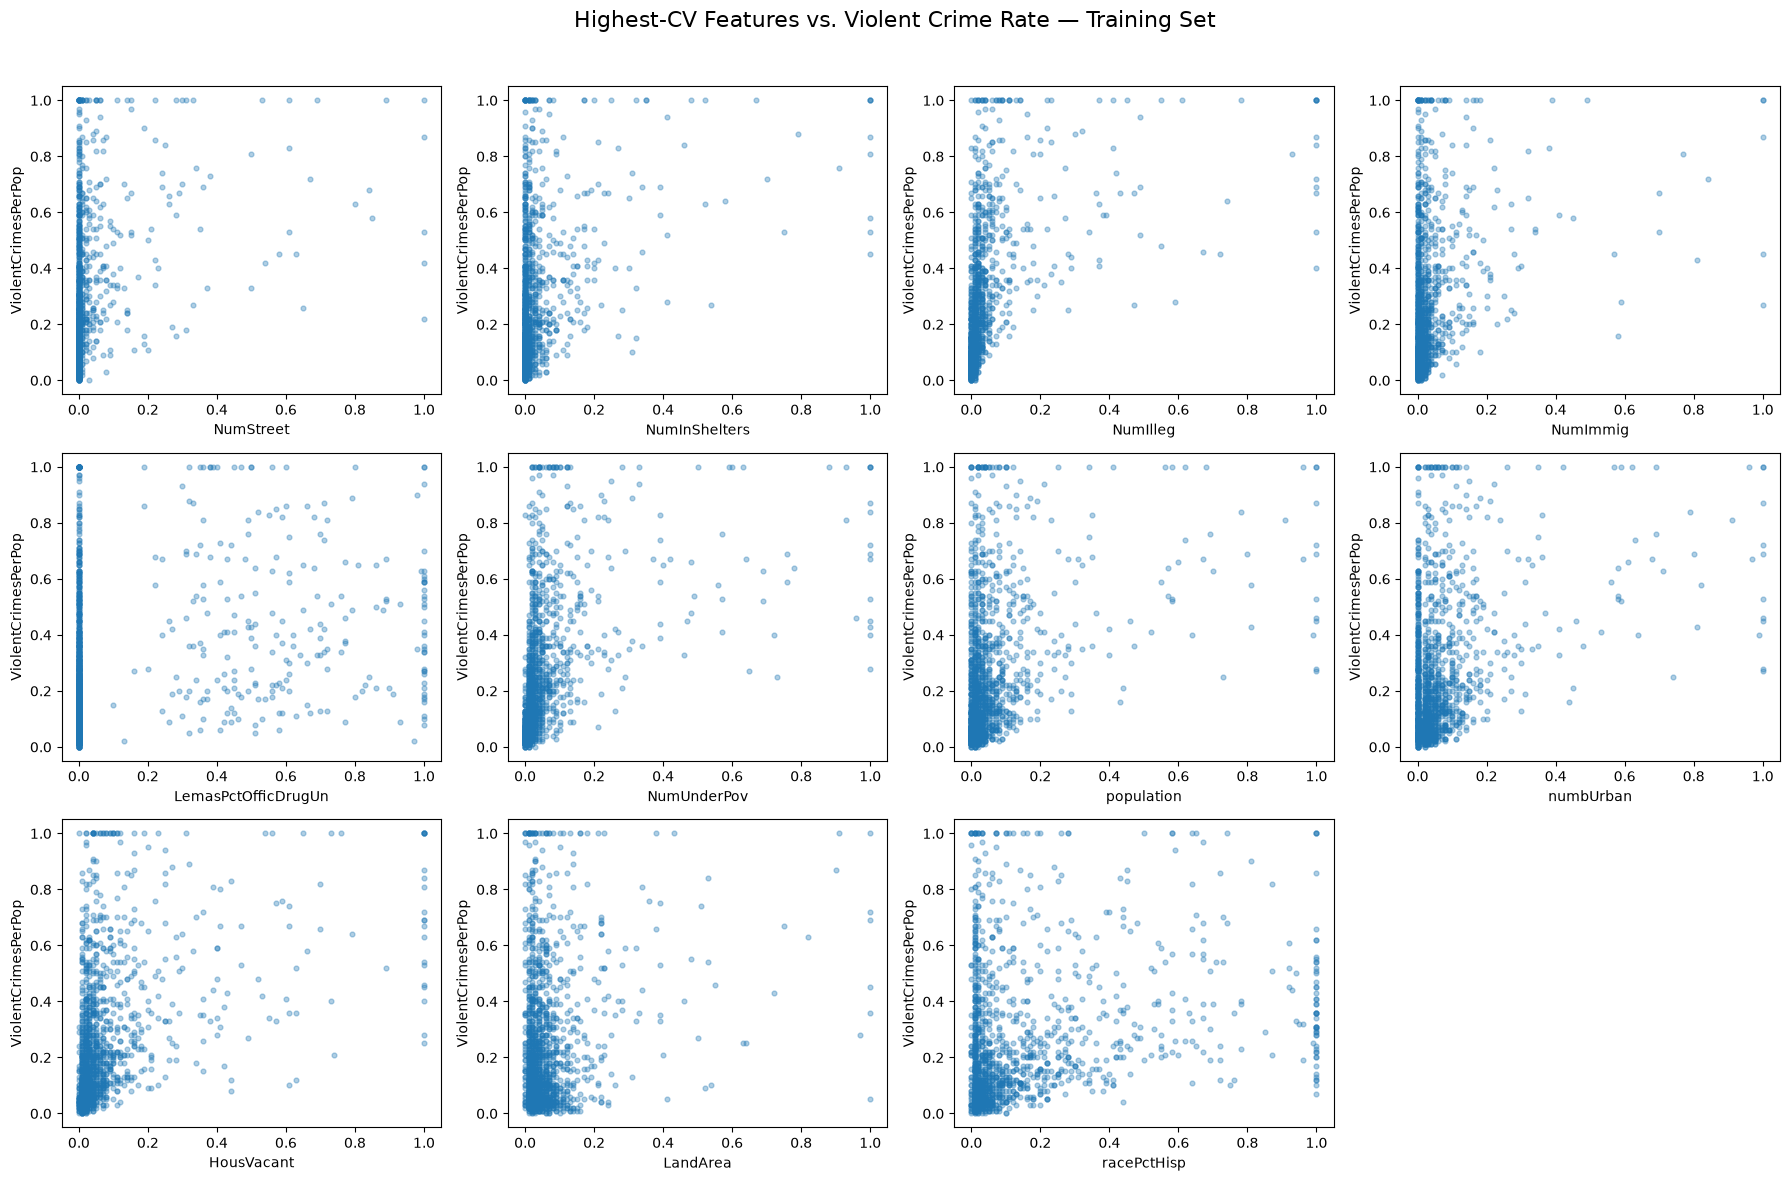

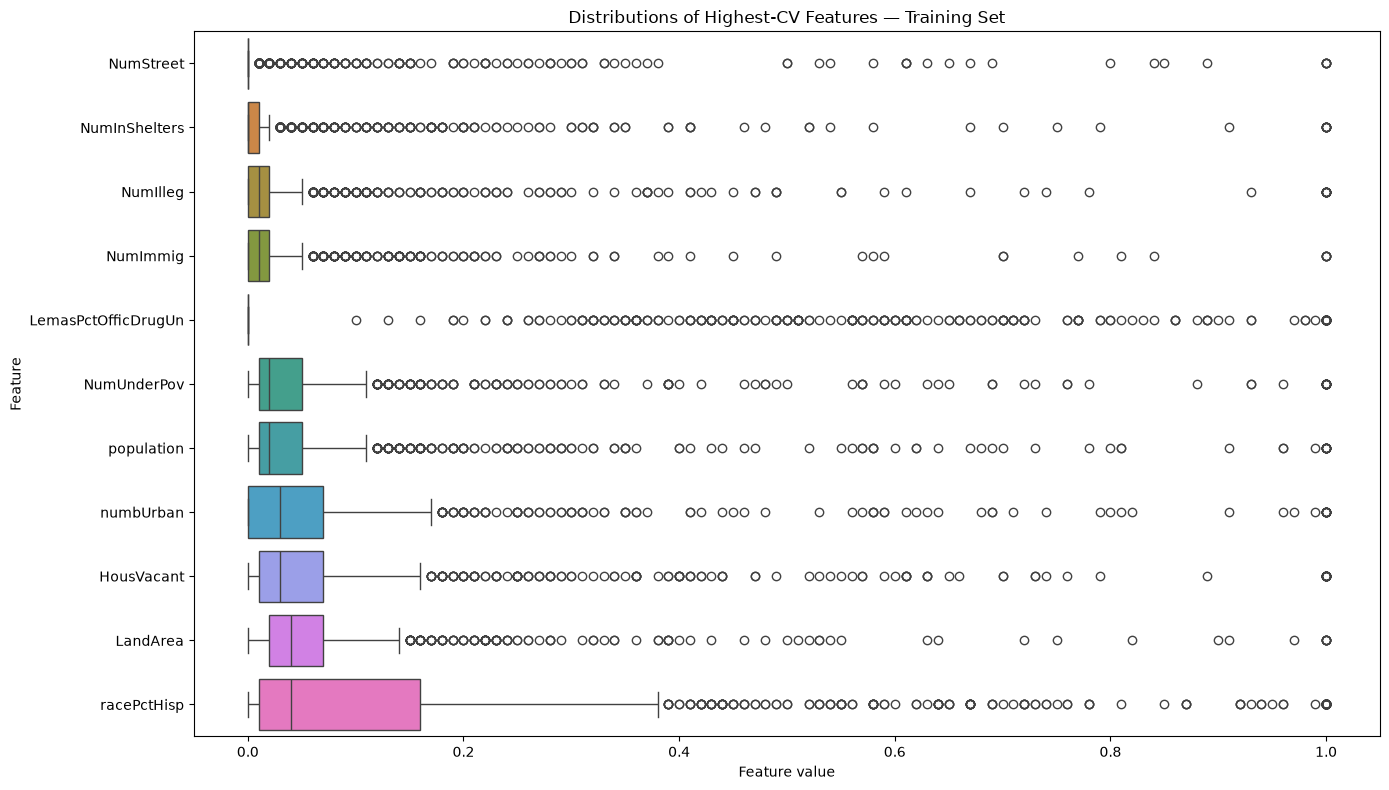

Number of selected features: 11


In [22]:
# Select the 11 features with the highest coefficients of variation.
n_selected = int(np.sqrt(128))

top_cv_features = (
    cv_summary["coefficient_of_variation"]
    .dropna()
    .head(n_selected)
    .index
    .tolist()
)

display(cv_summary.loc[top_cv_features])

# Plot each selected feature against the regression target.
fig, axes = plt.subplots(
    nrows=3,
    ncols=4,
    figsize=(18, 12),
)

for ax, feature in zip(axes.flat, top_cv_features):
    ax.scatter(
        X_train[feature],
        y_train,
        alpha=0.35,
        s=12,
    )
    ax.set_xlabel(feature)
    ax.set_ylabel("ViolentCrimesPerPop")

for ax in axes.flat[len(top_cv_features):]:
    ax.set_visible(False)

fig.suptitle(
    "Highest-CV Features vs. Violent Crime Rate — Training Set",
    fontsize=16,
)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

# Plot the distributions of the selected features.
plt.figure(figsize=(14, 8))

sns.boxplot(
    data=X_train[top_cv_features],
    orient="h",
    showfliers=True,
)

plt.title("Distributions of Highest-CV Features — Training Set")
plt.xlabel("Feature value")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

print("Number of selected features:", len(top_cv_features))

Most selected features have right-skewed distributions, with many
observations near zero and relatively few large values. This pattern
is particularly apparent for NumStreet and NumInShelters and helps
explain their high coefficients of variation.

The scatter plots show substantial variation in violent crime rates
among communities with similar feature values. The box plots also
identify many potential outliers, which do not necessarily represent
data errors.

Scatter plots alone cannot establish statistical significance because
they do not control for other predictors or provide formal statistical
tests. A high coefficient of variation describes relative variability,
not necessarily predictive importance.

### (f) Fit a linear model

In [23]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

# Fit ordinary least squares using all 122 predictors.
ols_model = LinearRegression()
ols_model.fit(X_train, y_train)

# Evaluate predictions on the training and test sets.
ols_train_predictions = ols_model.predict(X_train)
ols_test_predictions = ols_model.predict(X_test)

ols_train_mse = mean_squared_error(
    y_train,
    ols_train_predictions,
)
ols_test_mse = mean_squared_error(
    y_test,
    ols_test_predictions,
)

print("Number of predictors:", X_train.shape[1])
print("OLS training MSE:", f"{ols_train_mse:.6f}")
print("OLS test MSE:", f"{ols_test_mse:.6f}")

# Store test errors for the final model comparison.
model_results = {
    "OLS": {
        "test_mse": ols_test_mse,
    }
}

Number of predictors: 122
OLS training MSE: 0.016309
OLS test MSE: 0.018142


### (g) Fit a ridge regression model

In [24]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline

# Use the same cross-validation splits for regression model selection.
regression_cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

# Fit the imputer separately within each training fold.
ridge_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("ridge", Ridge()),
])

ridge_alpha_grid = np.logspace(-4, 4, 81)

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid={"ridge__alpha": ridge_alpha_grid},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1,
    refit=True,
)

ridge_search.fit(X_train_raw, y_train)

ridge_model = ridge_search.best_estimator_
ridge_best_alpha = ridge_search.best_params_["ridge__alpha"]
ridge_cv_mse = -ridge_search.best_score_

ridge_test_predictions = ridge_model.predict(X_test_raw)
ridge_test_mse = mean_squared_error(
    y_test,
    ridge_test_predictions,
)

print("Selected alpha:", f"{ridge_best_alpha:.6g}")
print("Best cross-validation MSE:", f"{ridge_cv_mse:.6f}")
print("Ridge test MSE:", f"{ridge_test_mse:.6f}")
print("OLS test MSE:", f"{ols_test_mse:.6f}")

model_results["Ridge"] = {
    "test_mse": ridge_test_mse,
}

if ridge_best_alpha in (
    ridge_alpha_grid[0],
    ridge_alpha_grid[-1],
):
    print("The selected alpha is at a search boundary; expand the grid.")

Selected alpha: 3.16228
Best cross-validation MSE: 0.019423
Ridge test MSE: 0.017555
OLS test MSE: 0.018142


### (h) Fit a LASSO model

In [25]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler

lasso_alpha_grid = np.logspace(-5, 0, 61)

lasso_searches = {}
lasso_selected_features = {}
lasso_comparison_rows = []

for model_name, scaler in [
    ("LASSO original scale", "passthrough"),
    ("LASSO standardized", StandardScaler()),
]:
    pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="mean")),
        ("scaler", scaler),
        ("lasso", Lasso(max_iter=100000, tol=1e-5)),
    ])

    search = GridSearchCV(
        estimator=pipeline,
        param_grid={"lasso__alpha": lasso_alpha_grid},
        scoring="neg_mean_squared_error",
        cv=regression_cv,
        n_jobs=-1,
        refit=True,
    )

    search.fit(X_train_raw, y_train)
    lasso_searches[model_name] = search

    best_model = search.best_estimator_
    best_alpha = search.best_params_["lasso__alpha"]

    predictions = best_model.predict(X_test_raw)
    test_mse = mean_squared_error(y_test, predictions)

    coefficients = pd.Series(
        best_model.named_steps["lasso"].coef_,
        index=X_train_raw.columns,
        name="coefficient",
    )

    selected = coefficients[coefficients != 0].sort_values(
        key=lambda values: values.abs(),
        ascending=False,
    )

    lasso_selected_features[model_name] = selected

    lasso_comparison_rows.append({
        "model": model_name,
        "alpha": best_alpha,
        "cv_mse": -search.best_score_,
        "test_mse": test_mse,
        "selected_features": len(selected),
    })

    model_results[model_name] = {"test_mse": test_mse}

    if best_alpha in (
        lasso_alpha_grid[0],
        lasso_alpha_grid[-1],
    ):
        print(
            f"{model_name}: selected alpha is at a search boundary; "
            "expand the grid."
        )

lasso_comparison = pd.DataFrame(
    lasso_comparison_rows
).set_index("model")

display(lasso_comparison)

for model_name, selected in lasso_selected_features.items():
    print(f"\n{model_name}")
    print(f"Selected features: {len(selected)}")
    print(selected.to_string())

,alpha,cv_mse,test_mse,selected_features
model,,,,
LASSO original scale,0.000121,0.019516,0.017744,75
LASSO standardized,0.000681,0.019639,0.017831,74



LASSO original scale
Selected features: 75
racepctblack             0.271437
agePct12t29             -0.256417
PctPersDenseHous         0.215567
PctKids2Par             -0.196805
NumStreet                0.165364
MedRent                  0.157367
RentLowQ                -0.156793
PctPopUnderPov          -0.139581
PctEmploy                0.132254
PctWorkMom              -0.128258
MalePctNevMarr           0.127980
HousVacant               0.122309
MalePctDivorce           0.115233
pctWRetire              -0.107476
PctIlleg                 0.099309
pctWInvInc              -0.096340
MedRentPctHousInc        0.089841
PolicReqPerOffic         0.088444
pctWWage                -0.081479
MedOwnCostPctIncNoMtg   -0.077146
FemalePctDiv            -0.073789
PctVacantBoarded         0.073054
PctNotSpeakEnglWell     -0.067937
NumImmig                -0.067735
LemasSwFTFieldPerPop     0.064848
agePct12t21              0.062665
PctHousOccup            -0.060996
PctVacMore6Mos          -0.059067
PctL

The original-scale LASSO selected 75 predictors and achieved a test
MSE of 0.017744. The standardized LASSO selected 74 predictors and
achieved a test MSE of 0.017831.

Standardization changed both the selected regularization parameter
and the number of retained predictors, but did not improve test MSE
in this experiment. Both LASSO models had lower test MSE than OLS,
while Ridge had the lowest test MSE among these models.

### (i) Fit a PCR model

Selected number of components: 60
Best cross-validation MSE: 0.020217
PCR test MSE: 0.018400


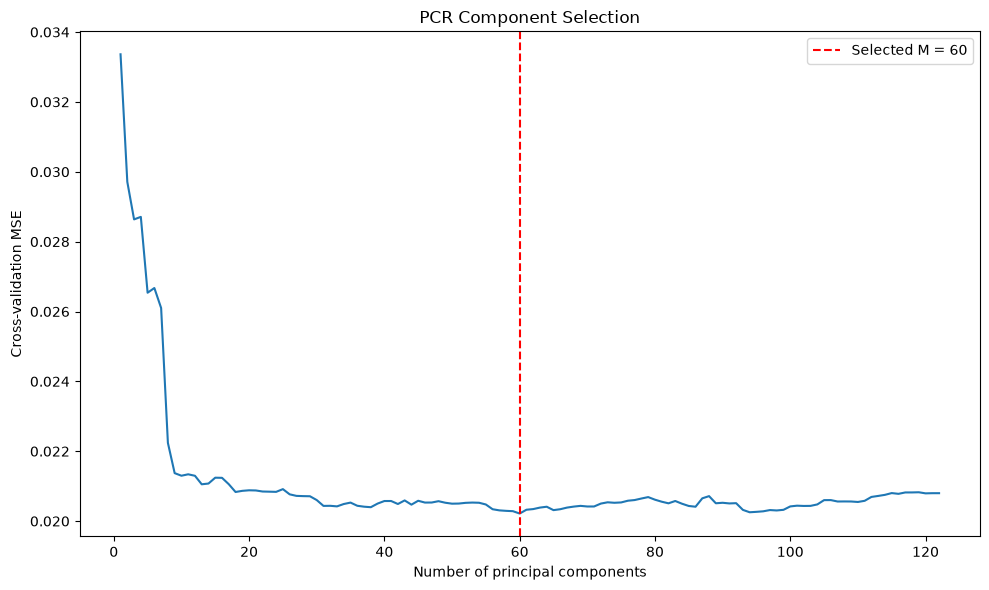

In [26]:
from sklearn.decomposition import PCA

pcr_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("scaler", StandardScaler()),
    ("pca", PCA(svd_solver="full")),
    ("regression", LinearRegression()),
])

# Evaluate every possible number of principal components.
component_grid = list(range(1, X_train_raw.shape[1] + 1))

pcr_search = GridSearchCV(
    estimator=pcr_pipeline,
    param_grid={"pca__n_components": component_grid},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1,
    refit=True,
)

pcr_search.fit(X_train_raw, y_train)

pcr_model = pcr_search.best_estimator_
pcr_best_components = pcr_search.best_params_["pca__n_components"]
pcr_cv_mse = -pcr_search.best_score_

pcr_test_predictions = pcr_model.predict(X_test_raw)
pcr_test_mse = mean_squared_error(
    y_test,
    pcr_test_predictions,
)

print("Selected number of components:", pcr_best_components)
print("Best cross-validation MSE:", f"{pcr_cv_mse:.6f}")
print("PCR test MSE:", f"{pcr_test_mse:.6f}")

model_results["PCR"] = {
    "test_mse": pcr_test_mse,
}

# Plot cross-validation error against the number of components.
pcr_cv_results = pd.DataFrame({
    "n_components": pcr_search.cv_results_[
        "param_pca__n_components"
    ].astype(int),
    "cv_mse": -pcr_search.cv_results_["mean_test_score"],
}).sort_values("n_components")

plt.figure(figsize=(10, 6))
plt.plot(
    pcr_cv_results["n_components"],
    pcr_cv_results["cv_mse"],
)
plt.axvline(
    pcr_best_components,
    color="red",
    linestyle="--",
    label=f"Selected M = {pcr_best_components}",
)
plt.xlabel("Number of principal components")
plt.ylabel("Cross-validation MSE")
plt.title("PCR Component Selection")
plt.legend()
plt.tight_layout()
plt.show()

### (j) Fit a boosting tree

In [29]:
from xgboost import XGBRegressor

# Fix other model settings and tune the L1 regularization strength.
xgb_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="mean")),
    ("xgb", XGBRegressor(
        objective="reg:squarederror",
        booster="gbtree",
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        min_child_weight=1,
        subsample=1.0,
        colsample_bytree=1.0,
        reg_lambda=1.0,
        tree_method="hist",
        random_state=42,
        n_jobs=1,
    )),
])

xgb_alpha_grid = np.concatenate([
    [0.0],
    np.logspace(-4, 2, 25),
])

xgb_search = GridSearchCV(
    estimator=xgb_pipeline,
    param_grid={"xgb__reg_alpha": xgb_alpha_grid},
    scoring="neg_mean_squared_error",
    cv=regression_cv,
    n_jobs=-1,
    refit=True,
)

xgb_search.fit(X_train_raw, y_train)

xgb_model = xgb_search.best_estimator_
xgb_best_alpha = xgb_search.best_params_["xgb__reg_alpha"]
xgb_cv_mse = -xgb_search.best_score_

xgb_test_predictions = xgb_model.predict(X_test_raw)
xgb_test_mse = mean_squared_error(
    y_test,
    xgb_test_predictions,
)

print("Selected L1 alpha:", f"{xgb_best_alpha:.6g}")
print("Best cross-validation MSE:", f"{xgb_cv_mse:.6f}")
print("XGBoost test MSE:", f"{xgb_test_mse:.6f}")

model_results["XGBoost"] = {
    "test_mse": xgb_test_mse,
}

if xgb_best_alpha == xgb_alpha_grid[-1]:
    print("The selected alpha is at the upper boundary; expand the grid.")

Selected L1 alpha: 0.177828
Best cross-validation MSE: 0.019908
XGBoost test MSE: 0.015988


In [32]:
comparison_table = (
    pd.DataFrame.from_dict(model_results, orient="index")
    .rename_axis("model")
    .sort_values("test_mse")
)

display(comparison_table)

,test_mse
model,
XGBoost,0.015988
Ridge,0.017555
LASSO original scale,0.017744
LASSO standardized,0.017831
OLS,0.018142
PCR,0.018400


Five-fold cross-validation selected an L1 regularization parameter
of 0.177828 for XGBoost. The corresponding mean cross-validation
MSE was 0.019908, and the test MSE was 0.015988.

The other XGBoost hyperparameters were held fixed during this search.
The L1 penalty was applied to tree leaf weights through reg_alpha.

### Model Comparison

| Model | Test MSE |
|---|---:|
| XGBoost | 0.015988 |
| Ridge | 0.017555 |
| LASSO, original scale | 0.017744 |
| LASSO, standardized | 0.017831 |
| OLS | 0.018142 |
| PCR | 0.018400 |

XGBoost achieved the lowest observed test MSE among the evaluated
models, approximately 11.9% lower than OLS.

Ridge and both LASSO models also had lower test MSE than OLS.
The original-scale LASSO retained 75 predictors, while the
standardized LASSO retained 74. Standardization did not improve
LASSO test performance in this experiment.

PCR selected 60 principal components but had a slightly higher
test MSE than OLS. Dimensionality reduction therefore did not
improve test performance in this experiment.

Hyperparameters were selected using training-set cross-validation.
The test errors summarize performance on the specified held-out
split and do not establish that one method will always outperform
the others.